# 5.5 · 风险指标与控制

> 量化投资中，"风险"不是一个数字，而是一整套指标。本节系统掌握衡量风险的指标（波动率、回撤、Beta、VaR、集中度、下行风险），以及风险控制的手段（止损、仓位、风险预算、限额）。
> 这是模块 5 的收尾，也是模块 6 回测、模块 7 实盘风控的基础。

## 一、风险指标体系

| 指标 | 含义 | 视角 |
|---|---|---|
| 波动率 σ | 收益标准差 | 总体波动 |
| 最大回撤 MDD | 从高点到低点的最大跌幅 | 极端亏损 |
| Beta | 相对市场的敏感度 | 系统性风险 |
| VaR | 给定置信度下的最大损失 | 尾部风险 |
| CVaR/ES | 尾部损失的平均 | 极端尾部 |
| 集中度 HHI / 有效持仓 | 权重集中程度 | 分散化 |
| 下行标准差 / Sortino | 只看下行波动 | 不对称风险 |
| 跟踪误差 TE | 相对基准的波动 | 主动风险 |

## 二、准备两个组合（Top30 小市值 vs 等权）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.library import build_factors
from portfolio_lab.weighting import topn_equal, equal_weight, portfolio_return
from portfolio_lab import metrics as RM
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
ret = close.pct_change()
facs = build_factors(close, F['$volume'].unstack('instrument'),
                     F['$mkt_cap_ard'].unstack('instrument'),
                     F['$pe_ttm'].unstack('instrument'),
                     F['$pb_lf'].unstack('instrument'))
sp = facs['SMB 小市值']
def run(weight_fn, start='2023-01-01'):
    out = {}; idx = sp.loc[start:].index
    for dt in idx[:-1]:
        i = sp.index.get_loc(dt)
        out[ret.index[i+1]] = portfolio_return(weight_fn(sp.iloc[i]), ret.iloc[i+1])
    return pd.Series(out)
top30 = run(lambda s: topn_equal(s, 30)); eqw = run(equal_weight)
mkt = ret.loc[eqw.index].mean(axis=1)
print('已构造组合，天数:', len(top30))

[25436:MainThread](2026-10-30 01:42:20,276) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[25436:MainThread](2026-10-30 01:42:21,721) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[25436:MainThread](2026-10-30 01:42:21,722) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


已构造组合，天数: 923


## 三、波动率与回撤

Top30  年化波动 0.264  最大回撤 -0.231
等权     年化波动 0.176  最大回撤 -0.190


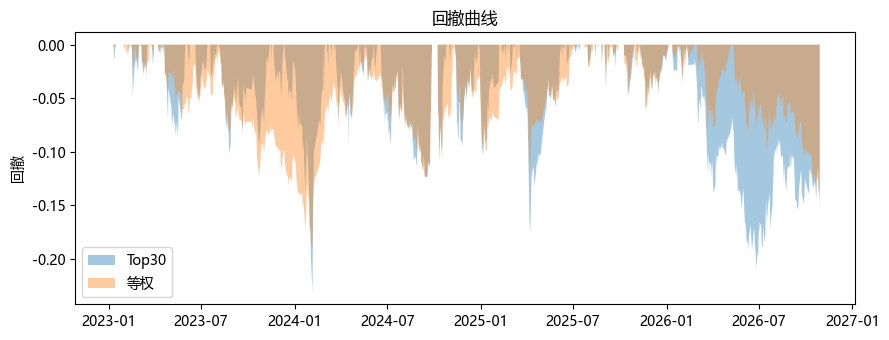

In [2]:
for name, r in [('Top30', top30), ('等权', eqw)]:
    print('%-6s 年化波动 %.3f  最大回撤 %.3f' %
          (name, RM.annual_vol(r), RM.max_drawdown(r)))
# 回撤曲线
plt.figure(figsize=(9, 3.5))
plt.fill_between(top30.index, RM.drawdown(top30), alpha=.4, label='Top30')
plt.fill_between(eqw.index, RM.drawdown(eqw), alpha=.4, label='等权')
plt.title('回撤曲线'); plt.ylabel('回撤'); plt.legend()
plt.tight_layout(); plt.show()

## 四、Beta：系统性风险

Beta 衡量组合相对市场的敏感度：$\beta = \mathrm{Cov}(r, r_m)/\mathrm{Var}(r_m)$。
- β=1 与市场同步；β>1 放大市场涨跌；β<1 更稳。

In [3]:
print('Top30 Beta %.3f   等权 Beta %.3f' %
      (RM.beta(top30, mkt), RM.beta(eqw, mkt)))

Top30 Beta 1.335   等权 Beta 1.000


## 五、VaR 与 CVaR：尾部风险

- **VaR（风险价值）**：在 95% 置信度下，单日损失不超过多少（收益的 5% 分位数）；
- **CVaR（条件 VaR / 期望损失 ES）**：当损失超过 VaR 时，平均损失多少（更能反映极端风险）。

> VaR 不告诉你"最坏情况有多坏"，CVaR 补充了尾部的平均损失。

Top30  VaR(95%) 0.0222  CVaR 0.0328
等权     VaR(95%) 0.0156  CVaR 0.0236


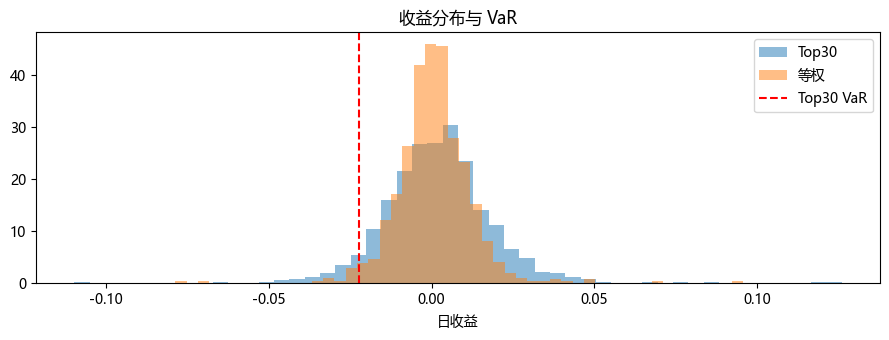

In [4]:
for name, r in [('Top30', top30), ('等权', eqw)]:
    print('%-6s VaR(95%%) %.4f  CVaR %.4f' %
          (name, RM.value_at_risk(r), RM.cvar(r)))
plt.figure(figsize=(9, 3.5))
plt.hist(top30, bins=50, alpha=.5, label='Top30', density=True)
plt.hist(eqw, bins=50, alpha=.5, label='等权', density=True)
plt.axvline(-RM.value_at_risk(top30), color='red', ls='--', label='Top30 VaR')
plt.title('收益分布与 VaR'); plt.xlabel('日收益'); plt.legend()
plt.tight_layout(); plt.show()

## 六、集中度与下行风险

In [5]:
w_top = topn_equal(sp.iloc[-2], 30); w_eq = equal_weight(sp.iloc[-2])
print('Top30: HHI %.4f  有效持仓 %.1f' % (RM.hhi(w_top), RM.effective_n(w_top)))
print('等权:  HHI %.4f  有效持仓 %.1f' % (RM.hhi(w_eq), RM.effective_n(w_eq)))
print('Sortino:  Top30 %.2f  等权 %.2f' %
      (RM.sortino(top30), RM.sortino(eqw)))

Top30: HHI 0.0333  有效持仓 30.0
等权:  HHI 0.0033  有效持仓 300.0
Sortino:  Top30 3.54  等权 1.20


## 七、风险控制手段

1. **止损（stop-loss）**：个股/组合跌破阈值减仓，控制单笔和回撤；
2. **仓位管理**：根据波动率/信号强度调整总仓位（如目标波动率、Kelly）；
3. **风险预算（risk budgeting）**：把风险（而非资金）分配给各资产/因子，如风险平价；
4. **分散化**：增加低相关资产、控制集中度（HHI/有效持仓）；
5. **风险限额**：VaR 限额、行业/风格暴露上限、回撤预警、杠杆上限；
6. **对冲**：用股指期货/期权对冲系统性风险（Beta 中性）。

> 实盘中（模块 7）这些会变成**事前（限额）、事中（监控）、事后（归因）**的完整风控体系。

## 八、小结与面试要点

- 风险指标：波动率、MDD、Beta、VaR/CVaR、集中度、下行风险（Sortino）、TE。
- 集中组合高波动、高 Beta、高尾部风险；分散组合更稳健。
- 风险控制：止损、仓位、风险预算、分散、限额、对冲。

**面试高频：**
- 常用的风险指标有哪些？（答：波动率、最大回撤、夏普、Beta、VaR/CVaR）
- VaR 和 CVaR 的区别？（答：VaR 是分位数，CVaR 是尾部平均，后者更能反映极端）
- Beta 衡量什么？（答：相对市场的系统性敏感度）
- 怎么控制组合风险？（答：分散、止损、仓位、风险预算、对冲、限额）
- 什么是风险平价？（答：按风险贡献而非资金分配权重）

## 动手练习
1. 计算不同 N 的组合的全部风险指标，画对比表；
2. 实现目标波动率仓位（波动大时降仓）；
3. 用沪深300 股指期货的思路，讨论如何把 Beta 降到 0。

---
模块 5 完成！下一模块 **6. 回测归因：严谨回测、交易成本、绩效归因（Brinson/多因子）**。